<a href="https://colab.research.google.com/github/GauthamAB/BIS/blob/main/GWO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 1 Best Delay: 44.0066
Iteration: 2 Best Delay: 43.3801
Iteration: 3 Best Delay: 43.2893
Iteration: 4 Best Delay: 43.2893
Iteration: 5 Best Delay: 43.2006
Iteration: 6 Best Delay: 43.0856
Iteration: 7 Best Delay: 43.0856
Iteration: 8 Best Delay: 42.9821
Iteration: 9 Best Delay: 42.9821
Iteration: 10 Best Delay: 42.9821
Iteration: 11 Best Delay: 42.9814
Iteration: 12 Best Delay: 42.9814
Iteration: 13 Best Delay: 42.9814
Iteration: 14 Best Delay: 42.9113
Iteration: 15 Best Delay: 42.9113
Iteration: 16 Best Delay: 42.9113
Iteration: 17 Best Delay: 42.9113
Iteration: 18 Best Delay: 42.9113
Iteration: 19 Best Delay: 42.9113
Iteration: 20 Best Delay: 42.9113
Iteration: 21 Best Delay: 42.9113
Iteration: 22 Best Delay: 42.9113
Iteration: 23 Best Delay: 42.9113
Iteration: 24 Best Delay: 42.9113
Iteration: 25 Best Delay: 42.9113
Iteration: 26 Best Delay: 42.9113
Iteration: 27 Best Delay: 42.9083
Iteration: 28 Best Delay: 42.9083
Iteration: 29 Best Delay: 42.9083
Iteration: 30 Best Dela

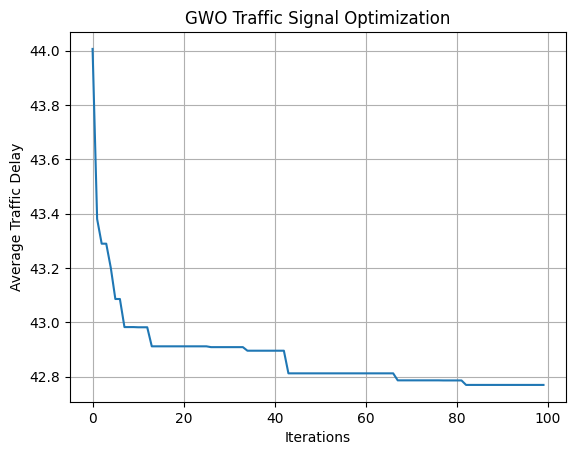

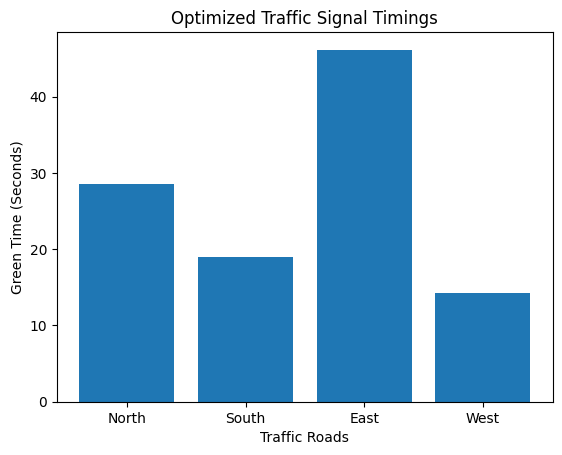

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Traffic junction details
roads = ["North", "South", "East", "West"]

# Vehicle arrival rates (vehicles per second)
traffic = np.array([0.12, 0.08, 0.14, 0.06])

# GWO parameters
population = 20
iterations = 100
dimension = 4

# Signal timing details
cycle_time = 120
amber_time = 3
total_green = cycle_time - 4 * amber_time

saturation_flow = 0.5  # Vehicles discharged per second


# Generate green timings from wolf positions
def get_green_times(position):
    weights = np.maximum(position, 0.001)
    weights = weights / np.sum(weights)

    # Minimum 10 seconds for each road
    green = 10 + weights * (total_green - 40)

    return green


# Fitness function: minimize average traffic delay
def fitness(position):
    green = get_green_times(position)

    total_delay = 0
    total_vehicles = 0

    for i in range(dimension):
        g = green[i]

        # Degree of saturation
        x = (traffic[i] * cycle_time) / (saturation_flow * g)

        # Approximate signal delay
        green_ratio = g / cycle_time

        denominator = 1 - min(x, 0.99) * green_ratio

        delay = (
            0.5 * cycle_time * (1 - green_ratio) ** 2
            / max(denominator, 0.01)
        )

        # Penalty for overloaded traffic lanes
        if x > 1:
            delay += 1000 * (x - 1) ** 2

        vehicles = traffic[i] * cycle_time

        total_delay += delay * vehicles
        total_vehicles += vehicles

    return total_delay / total_vehicles


# Grey Wolf Optimizer
def GWO():
    # Initialize wolves randomly
    wolves = np.random.uniform(0.1, 1.0,
                               (population, dimension))

    alpha = np.zeros(dimension)
    beta = np.zeros(dimension)
    delta = np.zeros(dimension)

    alpha_score = float("inf")
    beta_score = float("inf")
    delta_score = float("inf")

    convergence = []

    for iteration in range(iterations):

        # Evaluate each wolf
        for wolf in wolves:
            score = fitness(wolf)

            if score < alpha_score:
                delta_score = beta_score
                delta = beta.copy()

                beta_score = alpha_score
                beta = alpha.copy()

                alpha_score = score
                alpha = wolf.copy()

            elif score < beta_score:
                delta_score = beta_score
                delta = beta.copy()

                beta_score = score
                beta = wolf.copy()

            elif score < delta_score:
                delta_score = score
                delta = wolf.copy()

        # Decrease a from 2 to 0
        a = 2 - iteration * (2 / iterations)

        # Update wolf positions
        for i in range(population):

            A1 = 2 * a * np.random.rand(dimension) - a
            C1 = 2 * np.random.rand(dimension)

            D_alpha = abs(C1 * alpha - wolves[i])
            X1 = alpha - A1 * D_alpha

            A2 = 2 * a * np.random.rand(dimension) - a
            C2 = 2 * np.random.rand(dimension)

            D_beta = abs(C2 * beta - wolves[i])
            X2 = beta - A2 * D_beta

            A3 = 2 * a * np.random.rand(dimension) - a
            C3 = 2 * np.random.rand(dimension)

            D_delta = abs(C3 * delta - wolves[i])
            X3 = delta - A3 * D_delta

            wolves[i] = (X1 + X2 + X3) / 3

            # Keep positions within boundaries
            wolves[i] = np.clip(wolves[i], 0.1, 1.0)

        convergence.append(alpha_score)

        print("Iteration:", iteration + 1,
              "Best Delay:", round(alpha_score, 4))

    return alpha, alpha_score, convergence


# Run GWO
best_solution, best_delay, convergence = GWO()

# Display optimized signal timings
best_green = get_green_times(best_solution)

print("\nOPTIMIZED TRAFFIC SIGNAL TIMINGS")

for i in range(dimension):
    print(roads[i], "Green Time:",
          round(best_green[i], 2), "seconds")

print("\nMinimum Average Delay:",
      round(best_delay, 2), "seconds")


# Plot convergence graph
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Average Traffic Delay")
plt.title("GWO Traffic Signal Optimization")
plt.grid()
plt.show()


# Plot optimized green timings
plt.bar(roads, best_green)
plt.xlabel("Traffic Roads")
plt.ylabel("Green Time (Seconds)")
plt.title("Optimized Traffic Signal Timings")
plt.show()